### 1. my_utils.py 파일 작성 (변환 함수 + draw 함수)

In [ ]:
%%writefile my_utils.py

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100


# ============================================================
# 축 그리기 / 사각형 그리기
# ============================================================

def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)
  ax.axvline(0, color='black', alpha=0.3)
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')

def draw_rectangle(ax, p1, p2, p3, p4, color='tab:blue'):
  my_polygon = Polygon([p1, p2, p3, p4], facecolor=color, edgecolor='none')
  ax.add_patch(my_polygon)


# ============================================================
# 변환 함수 (동차좌표계 3x3 행렬)
# ============================================================

def to_h(p):
  return np.array([p[0], p[1], 1.0])

def to_2d(hq):
  return np.array([hq[0], hq[1]])

def translate(p, dx, dy):
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])
  return to_2d(np.dot(m, to_h(p)))

def rotate(p, theta):
  m = np.array([[np.cos(theta), -np.sin(theta), 0.0], [np.sin(theta), np.cos(theta), 0.0], [0.0, 0.0, 1.0]])
  return to_2d(np.dot(m, to_h(p)))

def scale(p, sx, sy):
  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])
  return to_2d(np.dot(m, to_h(p)))

def shear_x(p, sx):
  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
  return to_2d(np.dot(m, to_h(p)))

def shear_y(p, sy):
  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])
  return to_2d(np.dot(m, to_h(p)))

def reflect_x(p):   # x축 대칭
  m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
  return to_2d(np.dot(m, to_h(p)))

def reflect_y(p):   # y축 대칭 (좌우 반전)
  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
  return to_2d(np.dot(m, to_h(p)))

def apply(q, f, *args):
  return [f(qi, *args) for qi in q]

def centered(p1, p2, p3, p4):
  return apply([p1, p2, p3, p4], translate, -LEN/2, -LEN/2)


# ============================================================
# 둥근 모양 (타원) 그리기
# ============================================================

def draw_round(ax, p1, p2, p3, p4, cx, cy, rx, ry, color, n=40):
  h = 2*ry/n
  for i in range(n):
    y = -ry + h*(i + 0.5)
    w = 2*rx*np.sqrt(1 - (y/ry)**2)
    q = centered(p1, p2, p3, p4)
    q = apply(q, scale, w/LEN, h*1.05/LEN)
    q = apply(q, translate, cx, cy + y)
    draw_rectangle(ax, *q, color=color)


# ============================================================
# 개구리 파트 그리기
# ============================================================

FROG  = '#b5d68a'   # 개구리 연두색
LINE  = '#7fa35a'   # 진한 연두 (선)
PAD   = '#86b85f'   # 연잎
SHADE = '#6f9f4c'   # 연잎 위 그림자

def draw_lily_pad(ax, p1, p2, p3, p4):
  draw_round(ax, p1, p2, p3, p4, 0, -470, 680, 230, '#f2d4d4')   # 분홍 그림자
  draw_round(ax, p1, p2, p3, p4, 0, -430, 660, 210, PAD)         # 연잎
  draw_round(ax, p1, p2, p3, p4, 0, -390, 320,  70, SHADE)       # 개구리 그림자

def draw_legs(ax, p1, p2, p3, p4):
  for sign in [-1, 1]:
    draw_round(ax, p1, p2, p3, p4, sign*230, -290, 130, 110, FROG)

  q = centered(p1, p2, p3, p4)
  q = apply(q, scale, 1.8, 0.45)
  q = apply(q, shear_x, -0.8)
  q = apply(q, translate, -310, -375)
  draw_rectangle(ax, *q, color=FROG)
  draw_rectangle(ax, *apply(q, reflect_y), color=FROG)

  q = centered(p1, p2, p3, p4)
  q = apply(q, scale, 0.06, 1.4)
  q = apply(q, rotate, -np.pi/6)
  q = apply(q, translate, -250, -285)
  draw_rectangle(ax, *q, color=LINE)
  draw_rectangle(ax, *apply(q, reflect_y), color=LINE)

def draw_body(ax, p1, p2, p3, p4):
  draw_round(ax, p1, p2, p3, p4, 0, -200, 230, 200, FROG)

  q = centered(p1, p2, p3, p4)
  q = apply(q, scale, 0.06, 2.2)
  q = apply(q, rotate, np.pi/20)
  q = apply(q, translate, -85, -255)
  draw_rectangle(ax, *q, color=LINE)
  draw_rectangle(ax, *apply(q, reflect_y), color=LINE)

  for sign in [-1, 1]:
    draw_round(ax, p1, p2, p3, p4, sign*80, -375, 65, 28, FROG)

  for dx in [-22, 22]:
    q = centered(p1, p2, p3, p4)
    q = apply(q, scale, 0.05, 0.4)
    q = apply(q, translate, -80 + dx, -380)
    draw_rectangle(ax, *q, color=LINE)
    draw_rectangle(ax, *apply(q, reflect_y), color=LINE)

def draw_head(ax, p1, p2, p3, p4):
  draw_round(ax, p1, p2, p3, p4, 0, 70, 300, 210, FROG)
  for sign in [-1, 1]:
    draw_round(ax, p1, p2, p3, p4, sign*165, 215, 115, 105, FROG)

def draw_face(ax, p1, p2, p3, p4):
  for sign in [-1, 1]:
    draw_round(ax, p1, p2, p3, p4, sign*160, 225, 40, 42, '#1d2b14')
    draw_round(ax, p1, p2, p3, p4, sign*200, 110, 58, 34, '#f4a0a0')

  q = centered(p1, p2, p3, p4)
  q = apply(q, scale, 0.22, 0.22)
  q = apply(q, rotate, np.pi/4)
  q = apply(q, translate, -148, 240)
  draw_rectangle(ax, *q, color='white')
  draw_rectangle(ax, *apply(q, translate, 320, 0), color='white')

  q = centered(p1, p2, p3, p4)
  q = apply(q, scale, 0.5, 0.1)
  q = apply(q, rotate, -np.pi/5)
  q = apply(q, translate, -46, 150)
  draw_rectangle(ax, *q, color='#1d2b14')
  draw_rectangle(ax, *apply(q, reflect_y), color='#1d2b14')

  q = centered(p1, p2, p3, p4)
  q = apply(q, scale, 0.5, 0.1)
  q = apply(q, rotate, np.pi/5)
  q = apply(q, translate, -14, 150)
  draw_rectangle(ax, *q, color='#1d2b14')
  draw_rectangle(ax, *apply(q, reflect_y), color='#1d2b14')


# ============================================================
# 전체 물체 그리기
# ============================================================

def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_lily_pad(ax, p1, p2, p3, p4)
  draw_legs(ax, p1, p2, p3, p4)
  draw_body(ax, p1, p2, p3, p4)
  draw_head(ax, p1, p2, p3, p4)
  draw_face(ax, p1, p2, p3, p4)


Writing my_utils.py


### 2. my_utils 불러오기

In [ ]:
import matplotlib.pyplot as plt
from my_utils import *

### 변환 함수 확인

In [ ]:
p = np.array([100, 50])
print("translate(p, 10, 20) :", translate(p, 10, 20))
print("rotate(p, pi/2)      :", np.round(rotate(p, np.pi/2), 3))
print("scale(p, 2, 3)       :", scale(p, 2, 3))
print("shear_x(p, 1)        :", shear_x(p, 1))
print("shear_y(p, 1)        :", shear_y(p, 1))
print("reflect_x(p)         :", reflect_x(p))
print("reflect_y(p)         :", reflect_y(p))

translate(p, 10, 20) : [110.  70.]
rotate(p, pi/2)      : [-50. 100.]
scale(p, 2, 3)       : [200. 150.]
shear_x(p, 1)        : [150.  50.]
shear_y(p, 1)        : [100. 150.]
reflect_x(p)         : [100. -50.]
reflect_y(p)         : [-100.   50.]


### main

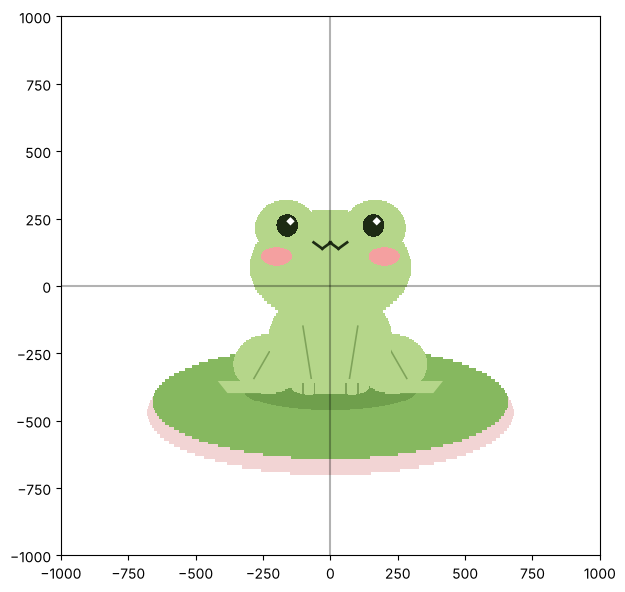

In [ ]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()